# EMNLP2026 FDiv Artifact Reproduction

This notebook executes the reproduction pipeline from raw checkpoint-only
inference artifacts. It does not start from completed paper tables.


In [21]:
from __future__ import annotations

import json
import importlib
import shutil
import subprocess
import sys
from datetime import datetime
from pathlib import Path

import pandas as pd
from IPython.display import Image, Markdown, display

ROOT = Path.cwd()
for candidate in [
    ROOT,
    *ROOT.parents,
]:
    if (candidate / "fsac").is_dir():
        ROOT = candidate
        break
else:
    raise RuntimeError("Cannot find FSAC repository root. Start the kernel from the repo or install with `pip install -e .`.")

if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import fsac.torgo.ger.reproduce_emnlp2026_fdiv as repro

repro = importlib.reload(repro)
PAPER_ROOT_DEFAULT = repro.PAPER_ROOT_DEFAULT
SOURCE_CONTROL_REF = repro.SOURCE_CONTROL_REF
SOURCE_LOSO = repro.SOURCE_LOSO
SOURCE_PERSONALIZED = repro.SOURCE_PERSONALIZED
aggregate_unified = repro.aggregate_unified
build_figures = repro.build_figures
build_report = repro.build_report
build_tables = repro.build_tables
build_unified_table = repro.build_unified_table
cells_from_manifest = repro.cells_from_manifest
cells_from_source = repro.cells_from_source
check_preconditions = repro.check_preconditions
latest_repro_root = repro.latest_repro_root
repo_display_path = repro.repo_display_path
validate_artifacts = repro.validate_artifacts
write_csv = repro.write_csv
write_text = repro.write_text


## Configuration

`ALLOW_SOURCE_RESULTS=False` is the strict mode: it requires completed FSAC
checkpoint-only reproduction roots. Set it to `True` only to rebuild the paper
artifacts directly from the original raw inference prediction/result files
while the checkpoint-only repro grid is incomplete.


In [22]:
PAPER_ROOT = PAPER_ROOT_DEFAULT
PERSONALIZED_REPRO_ROOT = latest_repro_root("personalized")
LOSO_REPRO_ROOT = latest_repro_root("loso")
ALLOW_SOURCE_RESULTS = True
TIMESTAMP = datetime.utcnow().strftime("notebook_%Y%m%d_%H%M%S")
OUT_DIR = ROOT / "results" / "paper_repro" / "emnlp2026_fdiv" / TIMESTAMP

print("ROOT:", ".")
print("PAPER_ROOT:", repo_display_path(PAPER_ROOT, ROOT))
print("SOURCE_PERSONALIZED:", repo_display_path(SOURCE_PERSONALIZED, ROOT))
print("SOURCE_LOSO:", repo_display_path(SOURCE_LOSO, ROOT))
print("SOURCE_CONTROL_REF:", repo_display_path(SOURCE_CONTROL_REF, ROOT))
print("PERSONALIZED_REPRO_ROOT:", repo_display_path(PERSONALIZED_REPRO_ROOT, ROOT))
print("LOSO_REPRO_ROOT:", repo_display_path(LOSO_REPRO_ROOT, ROOT))
print("ALLOW_SOURCE_RESULTS:", ALLOW_SOURCE_RESULTS)
print("OUT_DIR:", repo_display_path(OUT_DIR, ROOT))


ROOT: .
PAPER_ROOT: paper/emnlp2026_FDiv
SOURCE_PERSONALIZED: data/paper_personalized_train
SOURCE_LOSO: data/paper_loso_train
SOURCE_CONTROL_REF: data/paper_control_ref_ablation_train
PERSONALIZED_REPRO_ROOT: None
LOSO_REPRO_ROOT: None
ALLOW_SOURCE_RESULTS: True
OUT_DIR: results/paper_repro/emnlp2026_fdiv/notebook_20260525_173838


## Preflight

The strict path fails early unless personalized is 300/300 and LOSO is
240/240. The source fallback still rebuilds artifacts from raw
`predictions.csv`, `inference_results.json`, prompts, and FDS CSVs; it does
not read completed paper tables.


In [23]:
if not ALLOW_SOURCE_RESULTS and (PERSONALIZED_REPRO_ROOT is None or LOSO_REPRO_ROOT is None):
    raise RuntimeError("Missing checkpoint-only repro roots. Run the verify scripts first.")

preconditions = check_preconditions(PERSONALIZED_REPRO_ROOT, LOSO_REPRO_ROOT, ALLOW_SOURCE_RESULTS)
display(pd.DataFrame(preconditions))

if any(row["status"] == "fail" for row in preconditions):
    raise RuntimeError("Strict checkpoint-only precondition failed. Re-run verification or set ALLOW_SOURCE_RESULTS=True for raw source-output fallback.")


""


## Collect Raw Inference Cells

This cell enumerates the raw per-cell files used for reproduction. RRQFormer
and `.bak_*` artifacts are not collected.


In [24]:
if OUT_DIR.exists():
    shutil.rmtree(OUT_DIR)
OUT_DIR.mkdir(parents=True, exist_ok=True)

if ALLOW_SOURCE_RESULTS:
    cells = cells_from_source(SOURCE_PERSONALIZED, "personalized")
    cells += cells_from_source(SOURCE_LOSO, "loso")
else:
    cells = cells_from_manifest(PERSONALIZED_REPRO_ROOT, "personalized")
    cells += cells_from_manifest(LOSO_REPRO_ROOT, "loso")

cells = [c for c in cells if c.mode in {"plain", "fds_off", "vgate"} and c.pred.exists() and c.result_json.exists()]
manifest_rows = [dict(c.__dict__) for c in cells]
for row in manifest_rows:
    for key, value in list(row.items()):
        if isinstance(value, Path):
            row[key] = repo_display_path(value, ROOT)

write_csv(OUT_DIR / "_manifest.csv", manifest_rows)
write_text(
    OUT_DIR / "_manifest.json",
    json.dumps(
        {
            "personalized_root": repo_display_path(PERSONALIZED_REPRO_ROOT, ROOT),
            "loso_root": repo_display_path(LOSO_REPRO_ROOT, ROOT),
            "allow_source_results": ALLOW_SOURCE_RESULTS,
            "n_cells": len(cells),
        },
        indent=2,
    )
    + "\n",
)

manifest_df = pd.DataFrame(manifest_rows)
display(manifest_df.groupby(["dataset", "mode"]).size().rename("n_cells").reset_index())
display(manifest_df.head())


,dataset,mode,n_cells
0,loso,fds_off,80
1,loso,plain,80
2,loso,vgate,80
3,personalized,fds_off,100
4,personalized,plain,100
5,personalized,vgate,100


,dataset,setting,whisper,llm_tag,seed,mode,pred,result_json,prompts,frame_fds,fold,k
0,personalized,base+4B,base,qwen3_4b,123,plain,data/paper_personalized_train/base/qwen3_4b/se...,data/paper_personalized_train/base/qwen3_4b/se...,data/paper_personalized_train/base/qwen3_4b/se...,data/paper_personalized_train/base/qwen3_4b/se...,,
1,personalized,base+4B,base,qwen3_4b,123,fds_off,data/paper_personalized_train/base/qwen3_4b/se...,data/paper_personalized_train/base/qwen3_4b/se...,data/paper_personalized_train/base/qwen3_4b/se...,data/paper_personalized_train/base/qwen3_4b/se...,,
2,personalized,base+4B,base,qwen3_4b,123,vgate,data/paper_personalized_train/base/qwen3_4b/se...,data/paper_personalized_train/base/qwen3_4b/se...,data/paper_personalized_train/base/qwen3_4b/se...,data/paper_personalized_train/base/qwen3_4b/se...,,
3,personalized,base+4B,base,qwen3_4b,2024,plain,data/paper_personalized_train/base/qwen3_4b/se...,data/paper_personalized_train/base/qwen3_4b/se...,data/paper_personalized_train/base/qwen3_4b/se...,data/paper_personalized_train/base/qwen3_4b/se...,,
4,personalized,base+4B,base,qwen3_4b,2024,fds_off,data/paper_personalized_train/base/qwen3_4b/se...,data/paper_personalized_train/base/qwen3_4b/se...,data/paper_personalized_train/base/qwen3_4b/se...,data/paper_personalized_train/base/qwen3_4b/se...,,


## Build Unified Utterance-Seed Table

This is the core recomputation step. It joins Plain/FDS-off/VGate predictions,
recomputes WER components and Oracle@5 from prompts, attaches utterance FDS
and DIV, then assigns headroom/FDS/DIV bins.


In [25]:
unified = build_unified_table(cells)
write_csv(OUT_DIR / "analysis" / "unified_utterance_seed_table.csv", unified)
write_csv(OUT_DIR / "analysis" / "personalized_setting_severity_summary.csv", aggregate_unified(unified, "personalized"))
write_csv(OUT_DIR / "analysis" / "loso_setting_severity_summary.csv", aggregate_unified(unified, "loso"))

unified_df = pd.DataFrame(unified)
print("unified rows:", len(unified_df))
display(unified_df[["dataset", "setting", "seed", "fold", "filename", "severity", "plain_wer", "vgate_wer", "oracle5_wer", "plain_headroom", "plain_vs_vgate_gain", "frame_fds_mean", "nbest_diversity"]].head())


unified rows: 23180


,dataset,setting,seed,fold,filename,severity,plain_wer,vgate_wer,oracle5_wer,plain_headroom,plain_vs_vgate_gain,frame_fds_mean,nbest_diversity
0,personalized,tiny+4B,42,,F01_Session1_0008.wav,Severe,108.333333,91.666667,66.666667,41.666667,16.666667,85.943092,0.694044
1,personalized,tiny+4B,42,,F01_Session1_0022.wav,Severe,100.000000,100.000000,62.500000,37.500000,0.000000,84.212852,0.491667
2,personalized,tiny+4B,42,,F03_Session1_0012.wav,Moderate,42.857143,28.571429,28.571429,14.285714,14.285714,76.377777,0.279524
3,personalized,tiny+4B,42,,F03_Session1_0167.wav,Moderate,83.333333,83.333333,33.333333,50.000000,0.000000,75.065216,0.750000
4,personalized,tiny+4B,42,,F03_Session1_0195.wav,Moderate,0.000000,0.000000,0.000000,0.000000,0.000000,73.760872,0.200000


## Patch Train-Only FDS Scope Scores

The all-control reference scores are stored once under `_reference/`; the
train-only reference scores are stored beside each seed's all-control CSV as
`frame_dte_scores_train_only_ref.csv`. The original all-control
`frame_dte_scores.csv` files are left untouched.


In [26]:
ALL_CONTROL_FRAME_DTE_CSV = SOURCE_CONTROL_REF / "_reference" / "frame_dte_scores_all_control_ref.csv"
TRAIN_ONLY_FRAME_DTE_CSV = "frame_dte_scores_train_only_ref.csv"


def _raw_frame_score_mean(path: Path) -> float:
    payload = repro.np.load(str(path), allow_pickle=True)
    total = 0.0
    n_frames = 0
    for idx in range(len(payload["filenames"])):
        scores = payload[f"scores_{idx}"].astype("float64")
        total += float(scores.sum())
        n_frames += int(scores.size)
    return total / n_frames


def _weighted_frame_dte_mean(csv_path: Path) -> float:
    df = pd.read_csv(csv_path)
    mean_col = "frame_dte_mean" if "frame_dte_mean" in df.columns else "frame_fds_mean"
    weights = df["n_frames"].astype(float)
    return float((df[mean_col].astype(float) * weights).sum() / weights.sum())


def _all_control_fds_reference_mean() -> float:
    if ALL_CONTROL_FRAME_DTE_CSV.exists():
        return _weighted_frame_dte_mean(ALL_CONTROL_FRAME_DTE_CSV)
    candidates = [
        ROOT / "cache" / "whisper_embeddings" / "new" / "torgo_whisper_largev2" / "fds_cache" / "raw_frame_scores.npz",
        ROOT / "cache" / "whisper_embeddings" / "torgo_whisper_largev2" / "fds_cache" / "raw_frame_scores.npz",
    ]
    for path in candidates:
        if path.exists():
            return _raw_frame_score_mean(path)
    raise FileNotFoundError(f"Missing all-control reference CSV: {ALL_CONTROL_FRAME_DTE_CSV}")


def _train_only_fds_reference_mean() -> float:
    vals = []
    seen_seeds = set()
    for seed_dir in repro.control_ref_seed_dirs():
        seed = seed_dir.name.removeprefix("seed")
        if seed in seen_seeds:
            continue
        csv_path = seed_dir / "whisper_dte" / TRAIN_ONLY_FRAME_DTE_CSV
        vals.append(_weighted_frame_dte_mean(csv_path))
        seen_seeds.add(seed)
    return repro.mean(vals)


_original_render_control_scope_ablation = repro.render_control_scope_ablation


def _render_control_scope_ablation_with_train_only_csv(control_rows):
    rows, tex = _original_render_control_scope_ablation(control_rows)
    all_mean = _all_control_fds_reference_mean()
    train_mean = _train_only_fds_reference_mean()
    fixed_line = (
        f"\\multicolumn{{6}}{{l}}{{\\itshape \\quad All-control: {repro.fnum(all_mean)} "
        f"\\quad Train-only (avg. across seeds): {repro.fnum(train_mean)} "
        f"\\quad $\\Delta$: {repro.tex_gain(train_mean - all_mean)}}} {repro.LB}"
    )
    lines = [
        fixed_line
        if "All-control:" in line and "Train-only" in line and "\\multicolumn" in line
        else line
        for line in tex.splitlines()
    ]
    return rows, "\n".join(lines) + "\n"


repro.render_control_scope_ablation = _render_control_scope_ablation_with_train_only_csv
print("FDS scope distribution source patched:")
print("  all-control:", repro.fnum(_all_control_fds_reference_mean()))
print("  train-only:", repro.fnum(_train_only_fds_reference_mean()))


FDS scope distribution source patched:
  all-control: 46.98
  train-only: 48.31


## Generate Paper Tables and Figures

Tables are written as `.csv`, `.md`, and `.tex`. Figures are generated from
the unified table or copied only when the paper uses a static asset.


In [27]:
tables = build_tables(OUT_DIR, unified, cells)
figures = build_figures(OUT_DIR, unified, PAPER_ROOT)
validation = validate_artifacts(
    OUT_DIR,
    PAPER_ROOT,
    preconditions,
    tables,
    figures,
    strict_paper_match=not ALLOW_SOURCE_RESULTS,
)
write_csv(OUT_DIR / "_validation_report.csv", validation)
build_report(OUT_DIR, validation, tables, figures)

display(pd.DataFrame(validation))


,check,status,detail,path
0,tab_main,pass,generated table,results/paper_repro/emnlp2026_fdiv/notebook_20...
1,paper_match_tab_main,warn,paper reference table missing,paper/emnlp2026_FDiv/tables/tab_main.tex
2,tab_params,pass,generated table,results/paper_repro/emnlp2026_fdiv/notebook_20...
3,paper_match_tab_params,warn,paper reference table missing,paper/emnlp2026_FDiv/tables/tab_params.tex
4,tab_headroom_bins,pass,generated table,results/paper_repro/emnlp2026_fdiv/notebook_20...
5,paper_match_tab_headroom_bins,warn,paper reference table missing,paper/emnlp2026_FDiv/tables/tab_headroom_bins.tex
6,tab_headroom_modsev,pass,generated table,results/paper_repro/emnlp2026_fdiv/notebook_20...
7,paper_match_tab_headroom_modsev,warn,paper reference table missing,paper/emnlp2026_FDiv/tables/tab_headroom_modse...
8,tab_mechanism,pass,generated table,results/paper_repro/emnlp2026_fdiv/notebook_20...
9,paper_match_tab_mechanism,warn,paper reference table missing,paper/emnlp2026_FDiv/tables/tab_mechanism.tex


## Display Reproduced Tables


In [28]:
for table_name in [
    "tab_main",
    "tab_headroom_bins",
    "tab_headroom_modsev",
    "tab_mechanism",
    "tab_fds_perturb",
    "tab_fds_scope_ablation",
    "tab_fds_scope_headroom",
    "tab_fds_frame_variation",
    "tab_loso_appendix",
    "tab_loso_headroom_bins",
    "tab_loso_headroom_speakers",
    "tab_params",
]:
    display(Markdown(f"### {table_name}"))
    display(pd.read_csv(OUT_DIR / "tables" / f"{table_name}.csv"))


### tab_main

,Setting,Top-1,Oracle@5,Plain,VGate w/o FDS,VGate,Headroom,Gain
0,tiny+4B,119.38,19.58,27.67,27.46,27.67,8.08,-0.00
1,tiny+8B,119.38,19.58,24.69,24.90,24.88,5.10,-0.19
2,base+4B,93.76,16.83,23.72,23.84,23.57,6.89,0.15
3,base+8B,93.76,16.83,24.74,21.83,21.51,7.92,3.23
4,small+4B,36.38,11.70,16.28,17.96,16.16,4.58,0.12
5,small+8B,36.38,11.70,15.70,16.00,15.21,4.00,0.50
6,medium+4B,20.94,10.37,20.46,17.14,15.62,10.09,4.84
7,medium+8B,20.94,10.37,13.65,14.75,14.71,3.28,-1.06
8,large-v2+4B,23.46,9.65,16.89,13.18,14.67,7.24,2.22
9,large-v2+8B,23.46,9.65,11.97,12.94,12.66,2.31,-0.69


### tab_headroom_bins

,Headroom bin,n,Mean headroom,Plain WER,VGate WER,Gain
0,Low headroom,5434,-4.26,10.17,14.49,-4.32
1,Mid headroom,5433,0.00,5.06,6.22,-1.16
2,High headroom,5433,23.49,45.91,37.61,8.31


### tab_headroom_modsev

,Setting,Top-1,Oracle@5,Plain,VGate w/o FDS,VGate,Headroom,Gain
0,tiny+4B,309.99,47.17,104.00,78.91,70.14,56.83,33.85
1,tiny+8B,309.99,47.17,71.03,72.14,62.26,23.86,8.77
2,base+4B,204.99,39.62,85.79,71.59,68.26,46.17,17.54
3,base+8B,204.99,39.62,60.82,62.04,47.95,21.20,12.87
4,small+4B,90.68,25.31,40.95,61.93,44.84,15.65,-3.88
5,small+8B,90.68,25.31,42.06,50.72,38.62,16.76,3.44
6,medium+4B,56.05,21.31,76.91,77.03,51.39,55.60,25.53
7,medium+8B,56.05,21.31,35.74,46.28,36.07,14.43,-0.33
8,large-v2+4B,38.07,22.31,82.13,35.74,39.51,59.82,42.62
9,large-v2+8B,38.07,22.31,28.63,32.52,31.85,6.33,-3.22


... (14 outputs left out)

### tab_loso_headroom_speakers

,Speaker,n,Oracle@5,Plain,VGate,Headroom,Gain
0,F01,200,45.65,53.10,55.38,7.45,-2.28
1,F03,1380,8.32,11.02,12.89,2.71,-1.87
2,F04,670,1.54,2.33,3.11,0.79,-0.77
3,M01,890,38.51,47.70,50.48,9.19,-2.78
4,M02,910,35.83,43.20,44.00,7.37,-0.80
5,M03,950,3.27,2.02,2.52,-1.25,-0.50
6,M04,640,54.71,67.97,78.01,13.26,-10.04
7,M05,1240,23.46,55.27,54.05,31.82,1.22


### tab_params

,Adapter,A_L (K),A_W (K),Gate (K),Total (M),FDS
0,Plain,528.5,700.6,0.0,45.89,No
1,VGate w/o FDS,528.5,700.6,0.6,45.91,No
2,VGate,528.5,700.6,0.6,45.91,Yes


## Display Reproduced Figures


### figure_checks

,check,value,expected
0,headroom_gain_cells,40,40
1,headroom_r,0.8321,0.8321
2,severity_r,0.1248,0.1248
3,FDS=60-70_DIV=0.50+_n,208,208
4,FDS=60-70_DIV=0.50+_gain,48.71,48.71
5,FDS=70-75_DIV=0.50+_n,154,154
6,FDS=70-75_DIV=0.50+_gain,41.10,41.10
7,gate_high_low_delta,0.0124,0.0124
8,gate_high_low_ci,"[0.0107, 0.0141]","[0.0107, 0.0141]"


### fig_fds_vgate_clean.png

results/paper_repro/emnlp2026_fdiv/notebook_20260525_173838/figures/fig_fds_vgate_clean.png


[Open figure](results/paper_repro/emnlp2026_fdiv/notebook_20260525_173838/figures/fig_fds_vgate_clean.png)

### fig_headroom_gain.pdf

results/paper_repro/emnlp2026_fdiv/notebook_20260525_173838/figures/fig_headroom_gain.pdf


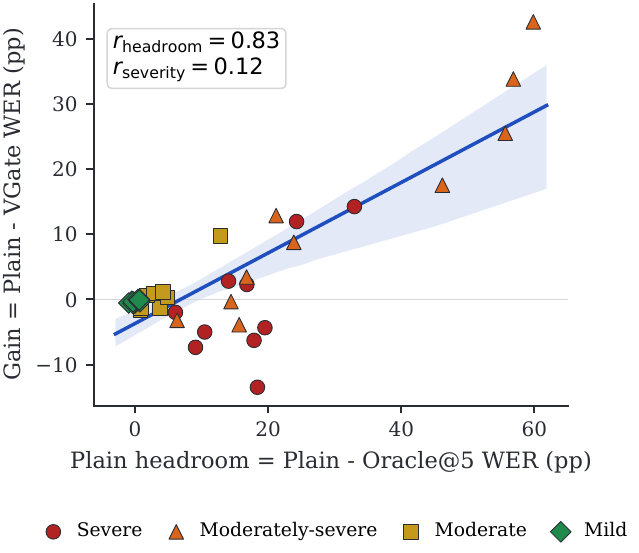

### fig_fds_bin_gain.pdf

results/paper_repro/emnlp2026_fdiv/notebook_20260525_173838/figures/fig_fds_bin_gain.pdf


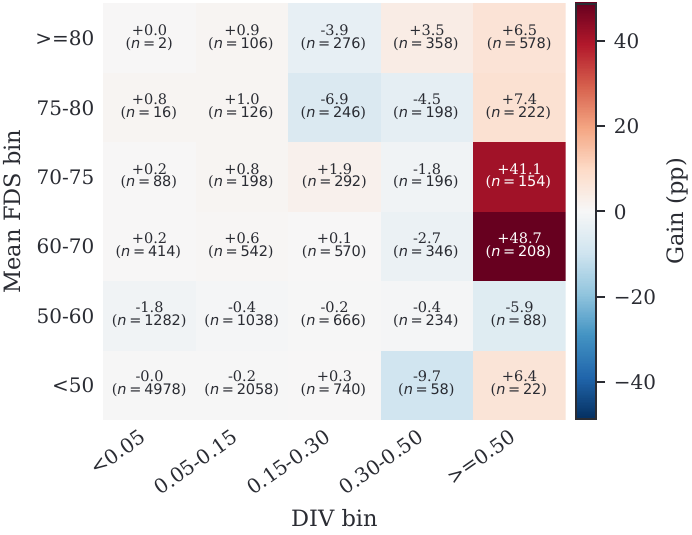

### fig_fds_gate_curve.pdf

results/paper_repro/emnlp2026_fdiv/notebook_20260525_173838/figures/fig_fds_gate_curve.pdf


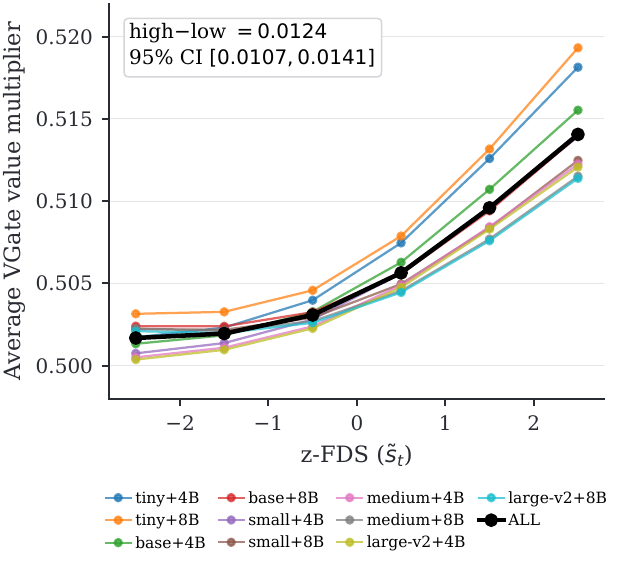

### fig_prompt_example.pdf

results/paper_repro/emnlp2026_fdiv/notebook_20260525_173838/figures/fig_prompt_example.pdf


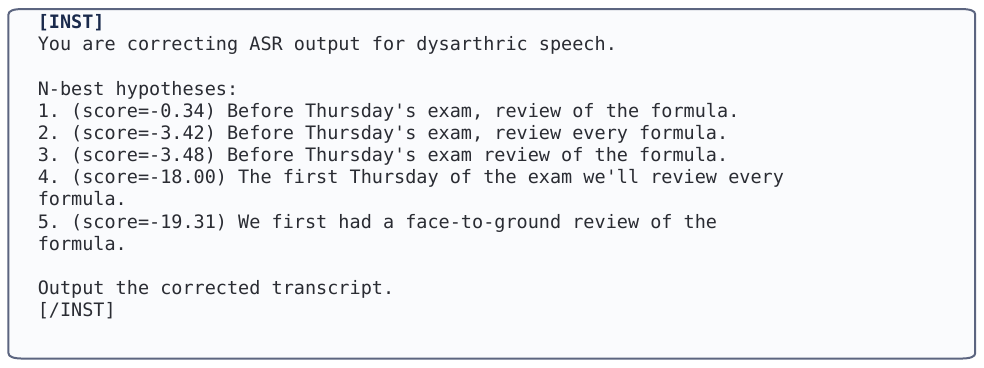

In [29]:
figure_checks = OUT_DIR / "analysis" / "figure_checks.csv"
if figure_checks.exists():
    display(Markdown("### figure_checks"))
    display(pd.read_csv(figure_checks))

for fig in [
    "fig_fds_vgate_clean.png",
    "fig_headroom_gain.pdf",
    "fig_fds_bin_gain.pdf",
    "fig_fds_gate_curve.pdf",
    "fig_prompt_example.pdf",
]:
    path = OUT_DIR / "figures" / fig
    display(Markdown(f"### {fig}"))
    print(repo_display_path(path, ROOT))
    preview = path.with_suffix(".png") if path.suffix.lower() == ".pdf" else path
    if path.suffix.lower() == ".pdf" and not preview.exists() and path.exists() and shutil.which("pdftoppm"):
        subprocess.run(["pdftoppm", "-png", "-singlefile", "-r", "180", str(path), str(path.with_suffix(""))], check=True)
    if preview.exists():
        display(Image(filename=str(preview)))
    else:
        display(Markdown(f"[Open figure]({repo_display_path(path, ROOT)})"))


## Output Directory


In [30]:
print(repo_display_path(OUT_DIR, ROOT))


results/paper_repro/emnlp2026_fdiv/notebook_20260525_173838
